# CV-inference-lab: MobileNetV4

This lab helping you out to understand what you need to do to make your model ready in productions. It means you are moving forward from the model in notebook into an applications that can be consumed by end users.

The lab doesn't teach you how to train, so in here we are going to use MobileNetV4 as the base model.

This model is originally trained using PyTorch but Youssef Boulaouane has converted to TensorFlow Lite

> [Find More on Hugging Face Here](https://huggingface.co/byoussef/MobileNetV4_Conv_Medium_TFLite_256)

## Step 1: Understanding the MobileNetV4

First things first, let's explore the models. MobileNetV4 is the computer vision model that was researched by Google Researcher and was publised at 16 April 2024.

What kind of model it is? It's a convolutional neural network architecture built for mobile and edge devices, achieving up to 75% reduction in parameters and running three to four times faster than earlier MobileNet varians while maintaining accuracy on ImageNet-1k.

The models is strong and was evaluated in two skills: image classification and object detection. However, in this specific lab, we will be focussing strictly on its image classification capability.

As the name mentioned, it's the 4th version of MobileNet. So there are some previous models that also was created by Google Researcher.

> [Find More about MobileNetV4 thru this Paper](https://arxiv.org/abs/2404.10518)

Since the paper exists and Google doesn't share the model file yet, the creator of PyTorch Image Models, Ross Wightman implemented the architecture in PyTorch and trained from scratch using ImageNet-1k dataset.

> [Find more the model from timm HERE](https://huggingface.co/timm/mobilenetv4_conv_medium.e500_r256_in1k)

In this lab we are going to use TensorFlow as the main framework, so the question is, is there any sources that make MobileNetV4 ready in TensorFlow?

> And I found [THIS](https://huggingface.co/byoussef/MobileNetV4_Conv_Medium_TFLite_256)

That source giving to you the MobileNetV4 that was converted to TensorFlow Lite by Youssef. AND... This lab will using that model version.

Let's go!

## Step 2: Install Dependency

We are going to use numpy and tensorflow as the main framework while the Image from PIL for inference testing.

In [7]:
import numpy as np
import tensorflow as tf

from PIL import Image

## Step 3: Understanding the Contract (Input)
When performing inference with an AI model, you need to understand the model contract. The contract defines what the model expects as input and how its output should be interpreted.

At the model interface, we can think of two main contracts:
* Input Contract
* Output Contract

### Input Contract
This contract defines the requirements that input data must satisfy before it can be passed to the model.

For CNN it may include:
* Input shape
* Data type
* Tensor Layout
* image size
* color format
* resizing and cropping strategy
* normalization
* quantization, etc.

If you are working with pretrained, there are some approaches.

1. **Runtime metadata**: Provide structural information such as shape, dtype, tensor index, layout-related information, and quantization paramters.
2. **Model configurations**: File such as config.json may define input size, interpolation, mean, std, crop configurations, and other preprocessing assumptions.
3. **Model information (README)**: Often provides recommended inference code and preprocessing intructions.
4. **Training and Evaluation pipeline**:
Helps you identify the input representation used when the model was trained and evaluated.

> Notes: If you are working with private model, the input contract should ideally be documented by the model owner or AI/ML engineering team. If documentation is unavailable, inspect the training, evaluation, preprocessing, and export pipelines to recounstruct the expected model input.

## Output Contract
The output contract defines the structure and meaning of the data produced by the model after inference.

Now, let's see the input and output contract through the runtime metadata.

In [8]:
# Download models
from huggingface_hub import hf_hub_download

model = hf_hub_download(
    repo_id="byoussef/MobileNetV4_Conv_Medium_TFLite_256",
    filename="mobilenetv4_conv_medium.e500_r256_in1k_float32.tflite"
)
print("=======================")

# Initialize interpreter and IO Details
tfl_interpret = tf.lite.Interpreter(model_path=model)
tfl_interpret.allocate_tensors()

# Read the input contract
input_contract = tfl_interpret.get_input_details()
print(f"This is the input contract \n {input_contract[0]}")
print("=======================")

# Read the output contract
output_contract = tfl_interpret.get_output_details()
print(f"This is the output contract \n {output_contract[0]}")
print("=======================")

# Explanation
print(f"""
EXPLANATION!!

The runtime metadata describes the structural properties of the model's input and output tensors, such as their tensor indices, shapes, data types, shape signatures, and quantization information.

For the input tensor, we can summarize the metadata as follows:
- Tensor index: 0
- Shape: [1, 256, 256, 3]
- Data type: np.float32
- The first dimension represents the batch size, while the remaining dimensions represent height, width, and RGB channels.

For the output tensor:
- Tensor index: 265
- Shape: [1, 1000]
- Data type: np.float32
- The model produces 1000 output values for each input sample. Based on the model configuration, these values correspond to the 1000 ImageNet classes.

Keep in mind that this runtime metadata only describes the structural part of the input and output contracts. Other information, such as preprocessing requirements or whether the output values are logits or probabilities, must be verified from the model configuration, documentation, or implementation.
""")

This is the input contract 
 {'name': 'inputs_0', 'index': 0, 'shape': array([  1, 256, 256,   3], dtype=int32), 'shape_signature': array([ -1, 256, 256,   3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}
This is the output contract 
 {'name': 'Identity', 'index': 265, 'shape': array([   1, 1000], dtype=int32), 'shape_signature': array([   1, 1000], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}

EXPLANATION!!

The runtime metadata describes the structural properties of the model's input and output tensors, such as their tensor indices, shapes, data types, shape signatures, and quantization information.

For the input tens

In [9]:
# Initialize interpreter and IO Details
MODEL_PATH=model
tfl_interpret = tf.lite.Interpreter(model_path=MODEL_PATH)
tfl_interpret.allocate_tensors()

## Step 3.1: Transforming image into acceptable np.array

Your model only accept data in a tensor format, however, end-users will provide raw image formats (such as JPEG or PNG), not tensors.

There is a gap in here, we must transform users raw image into a standardized tensors.

### Step 3.1.1: Load Image (User Input)

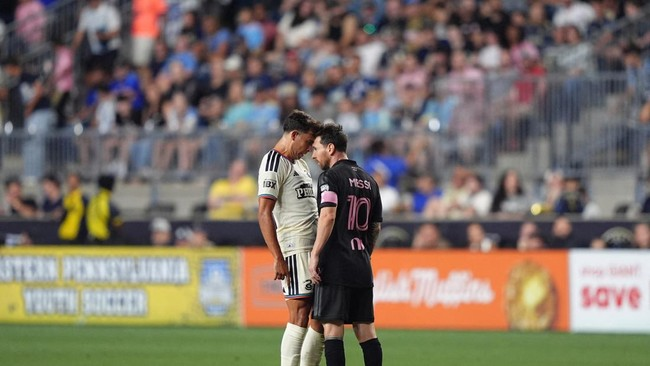

In [10]:
# Open Image (User Input)
image = Image.open("/content/fooot.jpeg")
image

### Step 3.1.2: Resize image

The first mindset that u need to have is making sure the image (input) has the same format with the input contract from model. How we know this?

Remember the informations from runtime metadata? The shape of image should be `[1, 256,256, 3]`

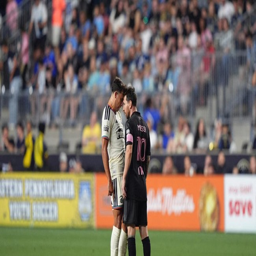

In [11]:
# Resizing image
image = image.resize((256,256),Image.BICUBIC) # BICUBIC is the interpolation method. Check the pretrained config for the info from timm: https://huggingface.co/timm/mobilenetv4_conv_medium.e500_r256_in1k/blob/main/config.json .
image

### Step 3.1.3: Transform image into np.array

In [12]:
# Transform the image into numpy array and check the shape
image = np.array(image, dtype=np.float32)
image.shape

(256, 256, 3)

### Step 3.1.4: Add batch dimension

The next step is to add a batch dimension, changing the image shape from (256, 256, 3) to (1, 256, 256, 3).

In [13]:
#Reposisi
image = np.expand_dims(image, axis=-1)
image = np.rollaxis(image, 3)

image.shape

(1, 256, 256, 3)

### Step 3.1.5: Standardizations

Next, we standardize the image using the mean and standard deviation defined in the model configuration.

The pixel values are first scaled from [0, 255] to [0, 1], then standardized per RGB channel.

In [14]:
# Standarisasi
mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229,0.224,0.225], dtype=np.float32)
image_norm = (image / 255.0 - mean) / std

In [15]:
# Final
image_norm.shape

(1, 256, 256, 3)

### Step 4: Make a Predictions

After your data already transformed into np.array, let's transform into tensor and make a predictions.

The cell below set your data into tensor index 0 (the input)

In [16]:
# Set data into tensor
tfl_interpret.set_tensor(
    input_contract[0]['index'],
    image_norm
)

After setting up, we giving the instructions to model to process the input using `invoke()`

In [17]:
tfl_interpret.invoke()

We need to take out the output through the output index.

In [18]:
tfl_output = tfl_interpret.get_tensor(output_contract[0]['index'])
tfl_output

array([[ -9.3441105,  -7.9482164,  -6.902269 ,  -8.54973  ,  -7.502459 ,
         -8.155991 ,  -8.568087 ,  -7.765136 ,  -8.448441 ,  -7.902501 ,
         -8.012142 ,  -8.540203 ,  -8.064184 ,  -8.609404 ,  -9.067395 ,
         -8.442253 ,  -8.068531 ,  -9.0585   ,  -7.796782 ,  -8.110289 ,
         -7.5700617,  -7.161388 ,  -6.8131733,  -7.6822677,  -6.752116 ,
         -7.320349 ,  -8.657076 ,  -7.888772 ,  -7.994466 ,  -8.013863 ,
         -7.2437224,  -8.039799 ,  -8.136915 ,  -7.359112 ,  -8.04165  ,
         -7.2305613,  -8.408211 ,  -7.77589  ,  -7.825988 ,  -7.9559216,
         -8.301851 ,  -9.374744 ,  -7.397957 ,  -6.624791 ,  -7.595503 ,
         -7.672723 ,  -8.123237 ,  -7.920945 ,  -8.024065 ,  -8.4474125,
         -7.785434 ,  -7.7478857,  -7.06072  ,  -7.4640946,  -7.3501635,
         -7.940201 ,  -7.5908766,  -7.48971  ,  -7.084735 ,  -9.009691 ,
         -6.974951 ,  -7.8353624,  -7.931883 ,  -7.106992 ,  -8.588759 ,
         -7.697083 ,  -7.102063 ,  -8.528529 ,  -7.

The output is using numpy array format, so we can transform it into tensor

In [19]:
tfl_output_tensor = tf.convert_to_tensor(tfl_output)

### Step 4.1 - The logits

Logits is the raw output scores that hasn't normalized yet. It was produced by the output layer of neural network.

Logits is uninterpretable because has wide range of number. If we see the minimum, maximum, and total tensor value. We can see how wide it is.

In [33]:
print(f"Min: {np.min(tfl_output_tensor)}")
print("============")
print(f"Max: {np.max(tfl_output_tensor)}")
print("============")
print(f"Sum: {np.sum(tfl_output_tensor)}")

Min: -10.495522499084473
Max: -0.5530222058296204
Sum: -7891.509765625


What's the solutions? we need to transform it into standarized value. We can using softmax to make the value into a range from -1 to 1.

In [21]:
tfl_output_softmax = tf.nn.softmax(tfl_output_tensor, axis=1)
tfl_output_softmax

<tf.Tensor: shape=(1, 1000), dtype=float32, numpy=
array([[4.70926789e-05, 1.90187755e-04, 5.41292247e-04, 1.04219354e-04,
        2.97010964e-04, 1.54506721e-04, 1.02323720e-04, 2.28398610e-04,
        1.15328847e-04, 1.99084039e-04, 1.78410293e-04, 1.05217012e-04,
        1.69362931e-04, 9.81821577e-05, 6.21053987e-05, 1.16044641e-04,
        1.68628336e-04, 6.26602850e-05, 2.21283815e-04, 1.61731805e-04,
        2.77595915e-04, 4.17732052e-04, 5.91732562e-04, 2.48131895e-04,
        6.28987851e-04, 3.56337696e-04, 9.36114084e-05, 2.01836127e-04,
        1.81591982e-04, 1.78103612e-04, 3.84716113e-04, 1.73543696e-04,
        1.57482282e-04, 3.42789426e-04, 1.73222739e-04, 3.89812893e-04,
        1.20063087e-04, 2.25955548e-04, 2.14914515e-04, 1.88727936e-04,
        1.33536756e-04, 4.56719172e-05, 3.29729024e-04, 7.14395661e-04,
        2.70622608e-04, 2.50511628e-04, 1.59651187e-04, 1.95445769e-04,
        1.76295769e-04, 1.15447474e-04, 2.23809300e-04, 2.32372680e-04,
        4.619

Now we can see the max number would be 1.

In [34]:
print(f"Min: {np.min(tfl_output_softmax)}")
print("============")
print(f"Max: {np.max(tfl_output_softmax)}")
print("============")
print(f"Sum: {np.sum(tfl_output_softmax)}")

Min: 1.4890235433995258e-05
Max: 0.3096524178981781
Sum: 1.0


### Step 4.2: The top labels output

The `tfl_output_softmax` stores the output labels. How we can know the best probabilities given by the models?

We can use the method from tensorflow `tf.math.top_k` by using `k=5` to see top 5 labels.

In [23]:
top_5_probs, top_5_indices = tf.math.top_k(tfl_output_softmax, k=5)
top_5_probs_list = top_5_probs.numpy().tolist()
top_5_idx_list = top_5_indices.numpy().tolist()

In [36]:
print(f"{top_5_idx_list}")
print("============")
print(f"{top_5_probs_list}")

[[981, 768, 560, 805, 429]]
[[0.3096524178981781, 0.13018153607845306, 0.1166483536362648, 0.04257725179195404, 0.033704835921525955]]


### Step 4.3: Make the output interperatable for human or apps

Cool! We finnaly found the output predictions But~ it's really hard to understand isn't?

How actually we can understand the output? mapping the output with labels that already given in the hugging face sources

In [27]:
# Download classes indices
from huggingface_hub import hf_hub_download

imagenet_classes = hf_hub_download(
    repo_id="byoussef/MobileNetV4_Conv_Medium_TFLite_256",
    filename="imagenet_classes.txt"
)

imagenet_classes.txt:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

In [37]:
# Read and store into a variable
with open(imagenet_classes, 'r') as f:
  classes = f.readlines()

In [38]:
classes

['tench\n',
 'goldfish\n',
 'great white shark\n',
 'tiger shark\n',
 'hammerhead\n',
 'electric ray\n',
 'stingray\n',
 'cock\n',
 'hen\n',
 'ostrich\n',
 'brambling\n',
 'goldfinch\n',
 'house finch\n',
 'junco\n',
 'indigo bunting\n',
 'robin\n',
 'bulbul\n',
 'jay\n',
 'magpie\n',
 'chickadee\n',
 'water ouzel\n',
 'kite\n',
 'bald eagle\n',
 'vulture\n',
 'great grey owl\n',
 'European fire salamander\n',
 'common newt\n',
 'eft\n',
 'spotted salamander\n',
 'axolotl\n',
 'bullfrog\n',
 'tree frog\n',
 'tailed frog\n',
 'loggerhead\n',
 'leatherback turtle\n',
 'mud turtle\n',
 'terrapin\n',
 'box turtle\n',
 'banded gecko\n',
 'common iguana\n',
 'American chameleon\n',
 'whiptail\n',
 'agama\n',
 'frilled lizard\n',
 'alligator lizard\n',
 'Gila monster\n',
 'green lizard\n',
 'African chameleon\n',
 'Komodo dragon\n',
 'African crocodile\n',
 'American alligator\n',
 'triceratops\n',
 'thunder snake\n',
 'ringneck snake\n',
 'hognose snake\n',
 'green snake\n',
 'king snake\n',

In [40]:
# Mapping index with labels
index_to_labels = {index: cls.strip() for index, cls in enumerate(classes)}
index_to_labels

{0: 'tench',
 1: 'goldfish',
 2: 'great white shark',
 3: 'tiger shark',
 4: 'hammerhead',
 5: 'electric ray',
 6: 'stingray',
 7: 'cock',
 8: 'hen',
 9: 'ostrich',
 10: 'brambling',
 11: 'goldfinch',
 12: 'house finch',
 13: 'junco',
 14: 'indigo bunting',
 15: 'robin',
 16: 'bulbul',
 17: 'jay',
 18: 'magpie',
 19: 'chickadee',
 20: 'water ouzel',
 21: 'kite',
 22: 'bald eagle',
 23: 'vulture',
 24: 'great grey owl',
 25: 'European fire salamander',
 26: 'common newt',
 27: 'eft',
 28: 'spotted salamander',
 29: 'axolotl',
 30: 'bullfrog',
 31: 'tree frog',
 32: 'tailed frog',
 33: 'loggerhead',
 34: 'leatherback turtle',
 35: 'mud turtle',
 36: 'terrapin',
 37: 'box turtle',
 38: 'banded gecko',
 39: 'common iguana',
 40: 'American chameleon',
 41: 'whiptail',
 42: 'agama',
 43: 'frilled lizard',
 44: 'alligator lizard',
 45: 'Gila monster',
 46: 'green lizard',
 47: 'African chameleon',
 48: 'Komodo dragon',
 49: 'African crocodile',
 50: 'American alligator',
 51: 'triceratops',
 

In [32]:
# Reconcilliation the labels with the index

for idx, prob in zip(top_5_idx_list[0], top_5_probs_list[0]):
  print(f"{index_to_labels[idx]}: {round(prob*100, 2)}%")

ballplayer: 30.97%
rugby ball: 13.02%
football helmet: 11.66%
soccer ball: 4.26%
baseball: 3.37%


# End

Perfect!! We can see the output from the predictions.